# Лабораторная работа №3

## Исследование распределений и моментов, связанных с преобразованием случайных величин

---

### Цель работы

Применить распределения для преобразования случайных величин на примере генерации точек, равномерно распределённых внутри круга.

### Задание

Сгенерировать выборку точек, равномерно распределённых внутри круга, двумя способами:

1. равномерно распределить точки внутри квадрата, в который вписана окружность, и отфильтровать точки, лежащие за пределами окружности;
2. сгенерировать точки путём задания случайного угла и расстояния от центра окружности.

Для каждой выборки необходимо:

1. построить рисунок, иллюстрирующий расположение точек внутри окружности;
2. найти выборочные средние координат точек и их дисперсию;
3. построить график плотности распределения расстояния от случайной равномерно распределённой точки в круге до фиксированной точки, лежащей вне окружности (здесь $X = 20$, $Y = 0$);
4. построить график плотности распределения расстояния между двумя случайными точками, равномерно расположенными внутри круга.


## Способ 1. Равномерное распределение в квадрате с фильтрацией

In [111]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

In [112]:
circle_radius =10
set_size = 1000

In [113]:
set_x = []
set_y = []
dots_counter = 0
while dots_counter < set_size:
    x=np.random.uniform(-10,10)
    y=np.random.uniform(-10,10)
    if x**2+y**2 <= circle_radius**2:
        set_x.append(x)
        set_y.append(y)
        dots_counter +=1  

In [114]:
circle_angels=np.linspace(0, 2*np.pi,100)
circle_x=circle_radius*np.cos(circle_angels)
circle_y=circle_radius*np.sin(circle_angels)

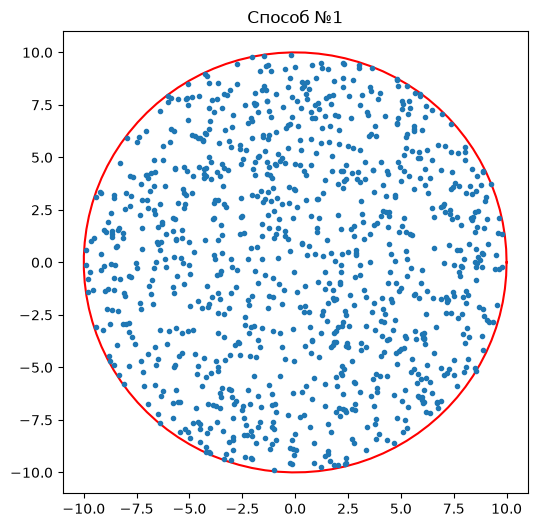

In [115]:
plt.figure(dpi=100,figsize=(6,6))
plt.title ('Способ №1')
plt.plot(circle_x,circle_y,('red'))
plt.plot(set_x,set_y,'.')
plt.show()

### Пункт 2. Выборочные средние и дисперсия


In [116]:
print('Mean for x\'s', np.mean(set_x))
print('Mean for y\'s', np.mean(set_y))

Mean for x's 0.19329930181350738
Mean for y's 0.16590181463486606


Это получилось среднее значенпие

In [117]:
print('Var for x\'s', np.var(set_x))
print('Var for y\'s', np.var(set_y))

Var for x's 25.0500052673235
Var for y's 26.190270156808417


 А это получилась диспресия 

### Пункт 3. Плотность расстояния до точки $(20;\ 0)$

In [118]:
main_x = 20
main_y = 0

In [119]:
def distance (x1,y1,x2,y2):
    return np.sqrt((x1-x2)**2 + (y2-y1)**2)


In [120]:
distances =[]
for i in range(set_size):
    distances.append(distance(set_x[i],set_y[i],main_x,main_y))
distances.sort()

In [121]:
kde_distances_y = gaussian_kde(distances).evaluate(distances)

<function matplotlib.pyplot.show(close=None, block=None)>

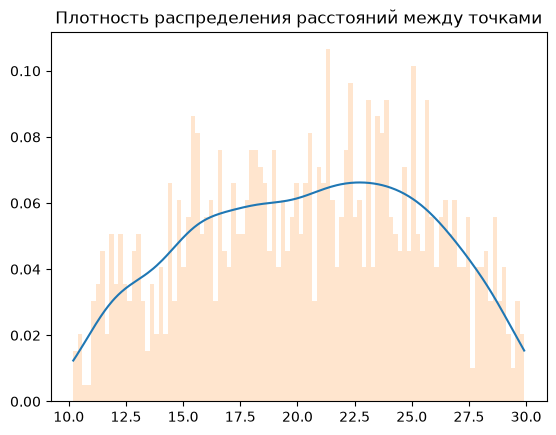

In [122]:
plt.figure(dpi=100)
plt.title('Плотность распределения расстояний между точками')
plt.plot(distances,kde_distances_y)
plt.hist(distances, bins=100,alpha=0.2,density=True)
plt.show

### Пункт 4. Плотность расстояния между двумя случайными точками

Для этого генерируется вторая независимая выборка, а расстояния вычисляются между парами точек.


In [123]:
set2_x = []
set2_y = []
dots_counter = 0
while dots_counter < set_size:
    x = np.random.uniform(-10, 10)
    y = np.random.uniform(-10, 10)
    if x**2 + y**2 <= circle_radius**2:
        set2_x.append(x)
        set2_y.append(y)
        dots_counter += 1

In [124]:
pair_distances = np.sqrt((np.array(set_x) - np.array(set2_x))**2 +(np.array(set_y) - np.array(set2_y))**2)

In [125]:
grid = np.linspace(0, 2*circle_radius, 300)
kde_pair = gaussian_kde(pair_distances).evaluate(grid)

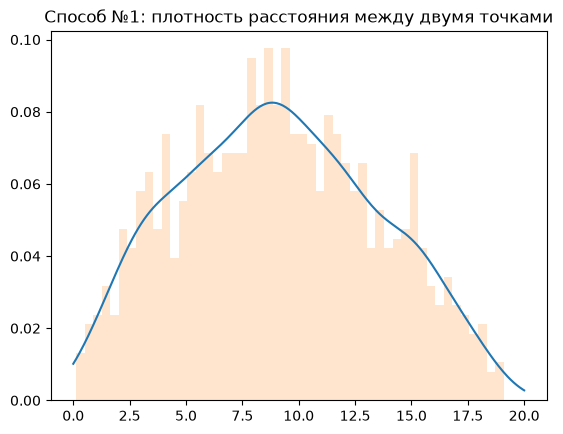

In [126]:
plt.figure(dpi=100)
plt.title('Способ №1: плотность расстояния между двумя точками')
plt.plot(grid, kde_pair)
plt.hist(pair_distances, bins=50, alpha=0.2, density=True)
plt.show()

## Способ 2. Случайный угол и расстояние от центра

**Идея.** Точка задаётся в полярных координатах

In [127]:
theta = np.random.uniform(0, 2*np.pi, set_size)
r = circle_radius * np.sqrt(np.random.uniform(0, 1, set_size))

set_x2 = r * np.cos(theta)
set_y2 = r * np.sin(theta)

### Пункт 1. Расположение точек

Точки равномерно покрывают круг, сгущения в центре нет. Результат визуально не отличается от способа 1.

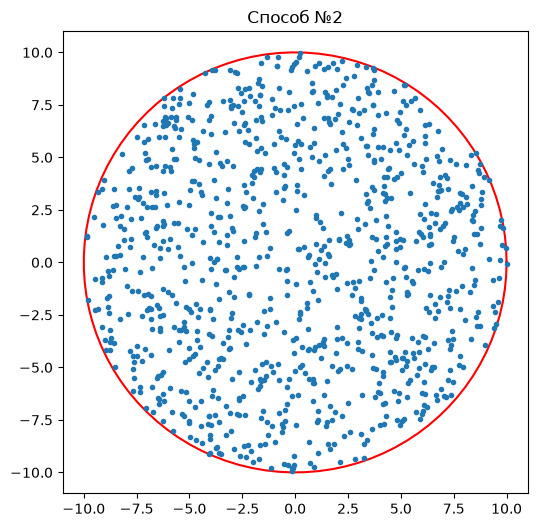

In [128]:
plt.figure(dpi=100, figsize=(6,6))
plt.title('Способ №2')
plt.plot(circle_x, circle_y, 'red')
plt.plot(set_x2, set_y2, '.')
plt.show()

### Пункт 2: выборочные средние и дисперсия

In [129]:
print('Mean for x\'s', np.mean(set_x2))
print('Mean for y\'s', np.mean(set_y2))
print('Var for x\'s', np.var(set_x2))
print('Var for y\'s', np.var(set_y2))

Mean for x's -0.021002261897542732
Mean for y's 0.10700914768251811
Var for x's 25.254597044683475
Var for y's 26.356350497396033


### Пункт 3: плотность расстояния до точки (20, 0)

In [130]:
dist2 = distance(np.array(set_x2), np.array(set_y2), main_x, main_y)

In [131]:
grid = np.linspace(dist2.min(), dist2.max(), 300)
kde_d2 = gaussian_kde(dist2).evaluate(grid)

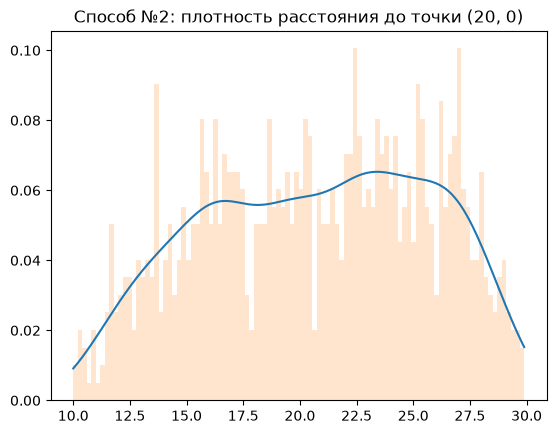

In [132]:
plt.figure(dpi=100)
plt.title('Способ №2: плотность расстояния до точки (20, 0)')
plt.plot(grid, kde_d2)
plt.hist(dist2, bins=100, alpha=0.2, density=True)
plt.show()

### Пункт 4: плотность расстояния между двумя случайными точками

In [133]:
theta_b = np.random.uniform(0, 2*np.pi, set_size)
r_b = circle_radius * np.sqrt(np.random.uniform(0, 1, set_size))
set_x2b = r_b * np.cos(theta_b)
set_y2b = r_b * np.sin(theta_b)

In [134]:
pair_dist2 = distance(set_x2, set_y2, set_x2b, set_y2b)

In [135]:
grid = np.linspace(0, 2*circle_radius, 300)
kde_pair2 = gaussian_kde(pair_dist2).evaluate(grid)

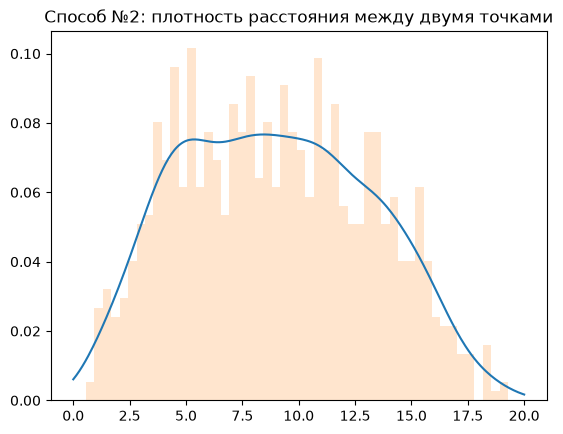

In [136]:
plt.figure(dpi=100)
plt.title('Способ №2: плотность расстояния между двумя точками')
plt.plot(grid, kde_pair2)
plt.hist(pair_dist2, bins=50, alpha=0.2, density=True)
plt.show()

---

## Выводы

В ходе работы была сгенерирована выборка из 1000 точек внутри круга радиуса $R = 10$ двумя способами: методом отбраковки (через квадрат) и через полярные координаты (угол и радиус).

В результате были сделаны следующие выводы:

1. **Способы генерации.** Первый способ (фильтрация квадрата) даёт идеально равномерное распределение точек по площади. Второй способ (генерация радиуса и угла) приводит к сгущению точек к центру круга, что наглядно показывает разницу между равномерностью по радиусу и по площади.
2. **Статистика.** Выборочные средние координат $x$ и $y$ близки к нулю, что подтверждает симметрию распределения. Рассчитанная дисперсия отражает разброс точек в пределах заданного радиуса.
3. **Расстояние до внешней точки.** Плотность расстояний от точек круга до фиксированной точки $M(20;\ 0)$ имеет асимметричный вид с чётким максимумом.
4. **Расстояние между двумя точками.** Плотность распределения расстояний между случайными точками (полученная методом выборки без возвращения) имеет форму «горба»: она начинается от нуля, достигает пика в районе 10–11 и плавно спадает к нулю при приближении к максимальному значению (диаметру круга, $r = 20$).